# 01 - The EAS instrument and its data

Everything the fit works with, shown on one real epoch:

0. the two sensor heads and their frames
1. counts
2. from counts to phase space density (PSD): the one-count level
3. magnetic field, pitch angle and the $(v_\parallel, v_\perp)$ grid
4. core, halo and strahl
5. the pitch-angle distribution (PAD)
6. spacecraft potential and the low-energy cut
7. the break energy
8. why zero-count pixels are data

**Runtime:** under a minute. Nothing is fitted here; the model curves come from the
reference run in `results/fitting/example_run_poisson/` (notebook 00 regenerates it).

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 0. The instrument: two heads, two frames

EAS sits at the end of the boom, in the shadow of the heat shield. Its two identical
top-hat analysers, **EAS1** and **EAS2**, are mounted at right angles and together see
almost the whole sky. Each head has

- 16 **elevation** bins (about $\pm$45 deg),
- 32 **azimuth** anodes (11.25 deg each),
- 64 logarithmic **energy** steps, about 1 eV to 5 keV,

so one epoch holds 2 x 16 x 32 x 64 = 65 536 measurements.

Pixel angles are defined in each head's own frame. One fixed rotation matrix per head
(`EAS1_TO_SRF`, `EAS2_TO_SRF`, from the L2 files) takes them to the **spacecraft
reference frame (SRF)**: $+X$ to the Sun, $+Z$ roughly solar north. MAG and PAS come in
SRF too, so the field-aligned grid of section 3 is built there. The tables are in
`examples/example_data/eas_head_geometry.npz` (written by `src/eas_geometry.py`).

The map shows the **velocity direction of the electrons** each pixel measures (the
pixel looks the opposite way), in the convention of Owen et al. (2020, A&A 642, A16,
Fig. 3): azimuth 0 = moving along $-X_\mathrm{SRF}$, away from the Sun, clockwise
positive ($+Y_\mathrm{SRF}$ at +90); elevation = latitude of the velocity.

EAS1: elevation -41.4..39.4 deg (16 bins), azimuth 32 anodes, energy 0.8..5292 eV (64 steps)
EAS1_TO_SRF =
[[ 0.    -0.707  0.707]
 [ 0.     0.707  0.707]
 [-1.     0.     0.   ]]
EAS2: elevation -41.2..39.0 deg (16 bins), azimuth 32 anodes, energy 0.8..5089 eV (64 steps)
EAS2_TO_SRF =
[[ 0.    -0.707  0.707]
 [ 0.    -0.707 -0.707]
 [ 1.     0.     0.   ]]
sky covered by the two heads: 141% of 4 pi sr


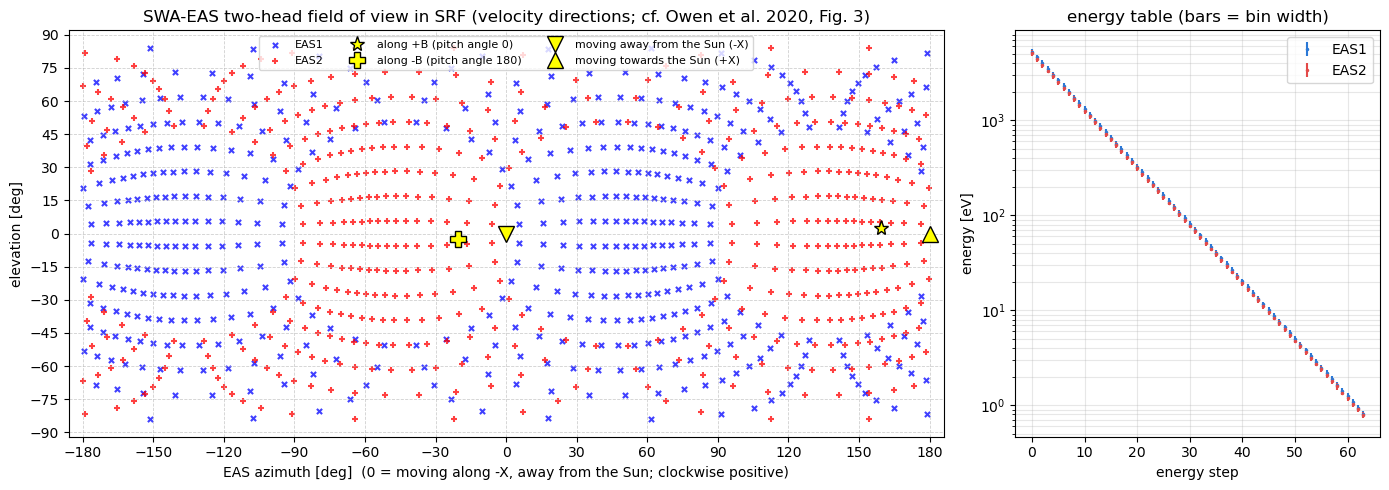

In [2]:
import h5py
from eas_geometry import (loadHeadGeometry, pixelUnitVectorsSrf, pixelSolidAngles,
                          pixelPitchAngles, easAzimuthElevation, HEAD_SLICES)

geometry = loadHeadGeometry(GEOMETRY_FILE)
for headName in ('EAS1', 'EAS2'):
    head = geometry[headName]
    print(f"{headName}: elevation {head['elevation_deg'].min():.1f}..{head['elevation_deg'].max():.1f} deg "
          f"({len(head['elevation_deg'])} bins), azimuth {len(head['azimuth_deg'])} anodes, "
          f"energy {head['energy_eV'].min():.1f}..{head['energy_eV'].max():.0f} eV ({len(head['energy_eV'])} steps)")
    print(f"{headName}_TO_SRF =\n{np.round(head['to_srf'], 3)}")

unitVectors = pixelUnitVectorsSrf(geometry)          # (1024, 3) velocity directions, in the pixel order of the files
pixelAzimuth, pixelElevation = easAzimuthElevation(unitVectors)
print(f'sky covered by the two heads: {pixelSolidAngles(geometry).sum() / (4 * np.pi):.0%} of 4 pi sr')

EPOCH = 20
with h5py.File(EXAMPLE_FILE, 'r') as h5:
    magneticField = h5['B_avg'][EPOCH]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2.4, 1]})
ax = axes[0]
for headName, marker, color in (('EAS1', 'x', 'blue'), ('EAS2', '+', 'red')):
    block = HEAD_SLICES[headName]
    ax.scatter(pixelAzimuth[block], pixelElevation[block], s=14, marker=marker, color=color, alpha=0.75, label=headName)
for vector, marker, label in ((magneticField, '*', 'along +B (pitch angle 0)'),
                              (-magneticField, 'P', 'along -B (pitch angle 180)'),
                              ((-1.0, 0.0, 0.0), 'v', 'moving away from the Sun (-X)'),
                              ((1.0, 0.0, 0.0), '^', 'moving towards the Sun (+X)')):
    azimuth, elevation = easAzimuthElevation(np.asarray(vector, float))
    ax.plot(azimuth, elevation, marker, color='k', markersize=11, markerfacecolor='yellow', label=label)
ax.set_xlim(-186, 186); ax.set_ylim(-92, 92)
ax.set_xticks(np.arange(-180, 181, 30)); ax.set_yticks(np.arange(-90, 91, 15))
ax.set_xlabel('EAS azimuth [deg]  (0 = moving along -X, away from the Sun; clockwise positive)')
ax.set_ylabel('elevation [deg]')
ax.grid(True, linestyle='--', linewidth=0.6, alpha=0.6); ax.legend(fontsize=8, loc='upper center', ncol=3)
ax.set_title('SWA-EAS two-head field of view in SRF (velocity directions; cf. Owen et al. 2020, Fig. 3)')
ax = axes[1]
for headName, color in (('EAS1', '#2a78d6'), ('EAS2', '#e34948')):
    head = geometry[headName]
    ax.errorbar(np.arange(64), head['energy_eV'], yerr=[head['energy_delta_lower_eV'], head['energy_delta_upper_eV']],
                fmt='.', color=color, label=headName, markersize=3)
ax.set_yscale('log'); ax.set_xlabel('energy step'); ax.set_ylabel('energy [eV]')
ax.grid(alpha=0.3, which='both'); ax.legend(); ax.set_title('energy table (bars = bin width)')
fig.tight_layout()

**Check.** The pitch angle of a pixel is the angle between its velocity direction and
**B**. Recomputing it from the geometry file and the field of the epoch reproduces the
values stored in the preprocessed file, so the conventions above (velocity direction,
head rotation, pixel order) are the ones the pipeline uses.

In [3]:
with h5py.File(EXAMPLE_FILE, 'r') as h5:
    storedPitchAngle = h5['pa_vec_in'][EPOCH, 30, :, 0]      # energy step 30, all 1024 pixels
recomputedPitchAngle = pixelPitchAngles(unitVectors, magneticField)
finite = np.isfinite(storedPitchAngle)
print(f'max |stored - recomputed| pitch angle over {int(finite.sum())} pixels: '
      f'{np.max(np.abs(storedPitchAngle[finite] - recomputedPitchAngle[finite])):.1e} deg')

max |stored - recomputed| pitch angle over 1024 pixels: 4.0e-04 deg


## 1. What EAS measures: counts

At each of the 64 energy steps, every pixel counts the electrons that arrive during the
accumulation time. The preprocessing (notebook 02) merges both heads into one grid of
**64 energies x 1024 pixels** per epoch and stores for every pixel its pitch angle, PSD,
$v_\parallel$, $v_\perp$ and the raw **counts**.

`loadEpoch` reads one epoch in CGS units.

In [4]:
from evdf_poisson import loadEpoch

EPOCH = 20
grid, psd, counts, epochNs, scDensity = loadEpoch(EXAMPLE_FILE, EPOCH)
epochTime = pd.Timestamp(int(epochNs))
print('epoch time:', epochTime)
print('grid arrays:', {key: value.shape for key, value in grid.items()})
print('valid pixels (finite velocity, above the low-energy cut):', int(grid['valid'].sum()))
print('RPW electron density n_sc = %.1f cm^-3' % scDensity)

epoch time: 2023-04-04 01:10:08
grid arrays: {'v_par': (64, 1024), 'v_perp': (64, 1024), 'pitch_angle': (64, 1024), 'one_count_psd': (64, 1024), 'energy_eV': (64, 1024), 'valid': (64, 1024)}
valid pixels (finite velocity, above the low-energy cut): 44032
RPW electron density n_sc = 24.3 cm^-3


Counts are small integers, and most of the grid registered **nothing**: above 100 eV,
three quarters or more of the pixels have zero counts. This is the regime where the
fitting objective matters (notebook 07).

In [5]:
ENERGY_BANDS_EV = [(0, 50), (50, 100), (100, 200), (200, 400), (400, 1000), (1000, 6000)]
rows = []
for low, high in ENERGY_BANDS_EV:
    inBand = grid['valid'] & (grid['energy_eV'] >= low) & (grid['energy_eV'] < high)
    bandCounts = counts[inBand]
    rows.append({'band_eV': f'{low}-{high}', 'pixels': inBand.sum(),
                 'zero_count_fraction': np.mean(bandCounts == 0),
                 'median_counts': np.median(bandCounts), 'max_counts': bandCounts.max()})
pd.DataFrame(rows).round(2)

,band_eV,pixels,zero_count_fraction,median_counts,max_counts
0,0-50,9728,0.11,2.0,12.0
1,50-100,4608,0.39,1.0,9.0
2,100-200,5120,0.83,0.0,11.0
3,200-400,5120,0.95,0.0,12.0
4,400-1000,7168,0.99,0.0,6.0
5,1000-6000,12288,1.00,0.0,1.0


## 2. From counts to PSD: the one-count level

A pixel that registered $C$ counts has the phase space density

$$ f = C \cdot g, \qquad g = \frac{m_e^2}{2\,\Delta t\, E^2\, G(\text{el},\text{az})\, Q(E)} $$

with $\Delta t$ the accumulation time, $G$ the geometric factor of the pixel and $Q$ the
detector efficiency.

$g$ is the **one-count level**: the PSD that a single count represents in that pixel. It
belongs to the instrument, not the plasma, and exists for every pixel, empty ones
included. That is what lets the Poisson fit use zero-count pixels: a model PSD becomes
an expected number of counts, $\mu = f_\text{model} / g$, to compare with the observed $C$.

The preprocessing evaluates $g$ from the geometric-factor and efficiency tables for
every pixel and stores it in the file (`one_count_psd_in`); `loadEpoch` reads it. Files
written before that field existed fall back to PSD / counts where counts > 0 (exact)
and the median of the energy row for empty pixels.

PSD / counts equals the stored one-count level on every detected pixel: True


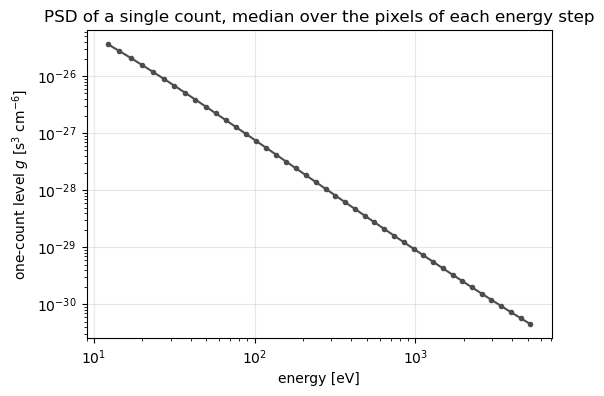

In [6]:
detected = grid['valid'] & (counts > 0)
print('PSD / counts equals the stored one-count level on every detected pixel:',
      np.allclose(psd[detected] / counts[detected], grid['one_count_psd'][detected], rtol=1e-9))

rowsWithData = [row for row in range(64) if grid['valid'][row].any()]
rowEnergy = [np.median(grid['energy_eV'][row][grid['valid'][row]]) for row in rowsWithData]
rowOneCount = [np.median(grid['one_count_psd'][row][grid['valid'][row]]) for row in rowsWithData]
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(rowEnergy, rowOneCount, 'o-', color='0.3', markersize=3)
ax.set_xlabel('energy [eV]'); ax.set_ylabel(r'one-count level $g$ [s$^3$ cm$^{-6}$]')
ax.set_title('PSD of a single count, median over the pixels of each energy step')
ax.grid(alpha=0.3)

## 3. Magnetic field, pitch angle, the gyrotropic grid

Electrons gyrate around **B**, so their distribution is close to symmetric about it. The
preprocessing rotates every pixel into the field-aligned frame (MAG averaged over the
epoch) and describes it by the **pitch angle** $\alpha$ between the electron velocity
and **B**:

$$ v_\parallel = v\cos\alpha, \qquad v_\perp = v\sin\alpha . $$

$\alpha = 0$ is along **B**, 180 deg against it. Below: the pixels in the
$(v_\parallel, v_\perp)$ half-plane, coloured by pitch angle. Every energy step is a
semicircle.

B (SRF, nT): [30.2  11.31  1.32]    proton bulk velocity (SRF, km/s): [-536.1  135.    -3.1]


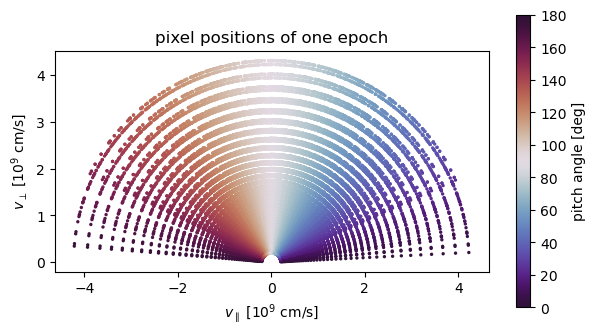

In [7]:
import h5py

with h5py.File(EXAMPLE_FILE, 'r') as h5:
    magneticField = h5['B_avg'][EPOCH]
    protonVelocity = h5['u'][EPOCH]
print('B (SRF, nT):', np.round(magneticField, 2), '   proton bulk velocity (SRF, km/s):', np.round(protonVelocity, 1))

valid = grid['valid']
fig, ax = plt.subplots(figsize=(7, 3.8))
scatterHandle = ax.scatter(grid['v_par'][valid] / 1e9, grid['v_perp'][valid] / 1e9,
                           c=grid['pitch_angle'][valid], s=2, cmap='twilight_shifted', vmin=0, vmax=180)
ax.set_aspect('equal'); ax.set_xlabel(r'$v_\parallel$ [$10^9$ cm/s]'); ax.set_ylabel(r'$v_\perp$ [$10^9$ cm/s]')
fig.colorbar(scatterHandle, ax=ax, label='pitch angle [deg]')
ax.set_title('pixel positions of one epoch');

`plotMeasuredVdf` is the standard view of these notebooks:

- **left:** the parallel cut, channel means of the pixels within 15 deg of **B**
  ($v_\parallel > 0$) and within 15 deg of $-$**B** ($v_\parallel < 0$);
- **middle:** the perpendicular cut (pitch angles 75-105 deg);
- **right:** the binned 2D distribution.

Zero-count pixels enter the means as zeros; the error bars are Poisson. The bump at
negative $v_\parallel$ is the **strahl**, a beam streaming away from the Sun along the
field.

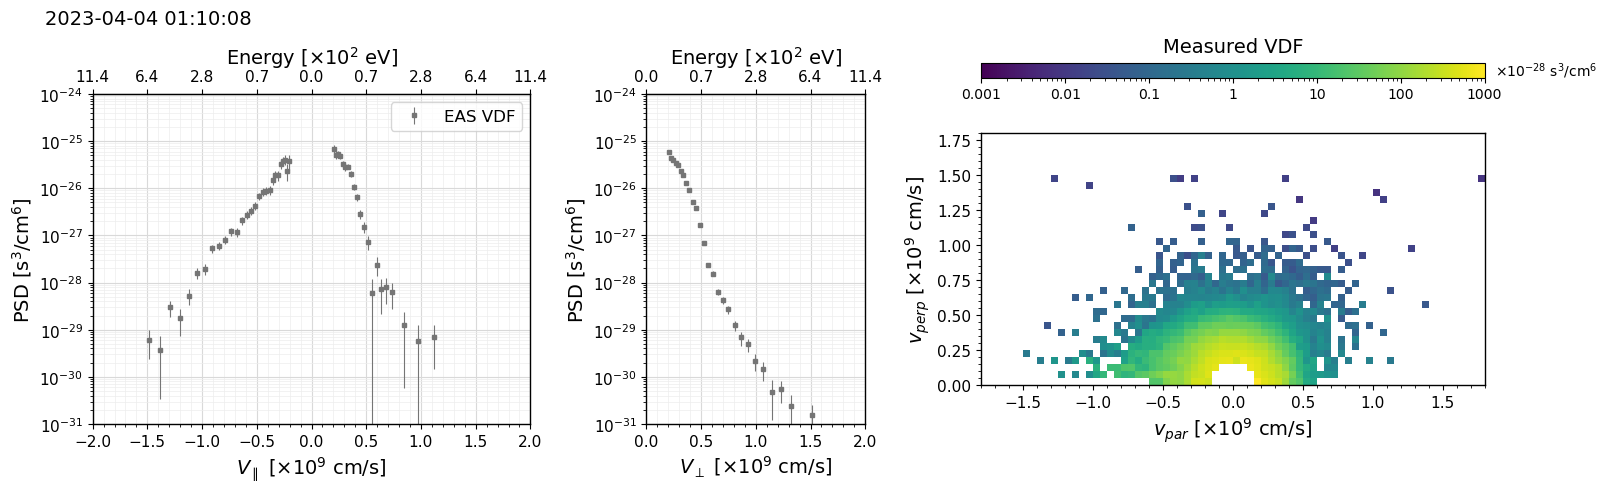

In [8]:
from evdf_poisson.plotting import plotMeasuredVdf

fig = plotMeasuredVdf(grid, psd, counts, timeLabel=str(epochTime))

## 4. The three populations

The standard description (e.g. Stverak et al. 2009, Owen et al. 2022):

| component | model | parameters | typical share |
|---|---|---|---|
| **core** | bi-Maxwellian | $n_c$, $u_{\parallel c}$, $T_{\parallel c}$, $T_{\perp c}$ | > 90 % of the density, below ~60-100 eV |
| **halo** | bi-kappa | $n_h$, $u_{\parallel h}$, $T_{\parallel h}$, $T_{\perp h}$, $\kappa_h$ | a few %, the near-isotropic high-energy tail |
| **strahl** | drifting, truncated bi-kappa | $n_b$, $u_{\parallel b}$, $T_{\parallel b}$, $T_{\perp b}$, $\kappa_b$ | ~1 %, a narrow beam along $\pm$**B** |

Bi-Maxwellian:

$$ f_c(v_\parallel, v_\perp) = \frac{n_c}{\pi^{3/2} v_{th\parallel} v_{th\perp}^2}
   \exp\!\left[-\frac{(v_\parallel - u_\parallel)^2}{v_{th\parallel}^2} - \frac{v_\perp^2}{v_{th\perp}^2}\right],
   \qquad v_{th} = \sqrt{2 k_B T / m_e}. $$

Bi-kappa: the exponential is replaced by
$\left[1 + \frac{(v_\parallel - u_\parallel)^2}{(\kappa - 3/2) v_{th\parallel}^2} + \frac{v_\perp^2}{(\kappa - 3/2) v_{th\perp}^2}\right]^{-\kappa - 1}$
times a $\kappa$-dependent normalisation. Small $\kappa$ is a hard power-law tail;
$\kappa \to \infty$ recovers the Maxwellian. With the $(\kappa - 3/2)$ convention, $T$
means the same for every component.

Strahl: a bi-kappa centred at the drift $u_{\parallel b}$ whose parallel width is
compressed by $\sqrt{5}$ on the side facing the core, so the beam does not leak into
the core.

The functions are in `evdf_poisson/models.py` (details in notebook 04). Below they are
drawn with the reference fit of this epoch.

,reference fit
n_c,9.361000e+00
u_par_c,-4.722681e+06
T_par_c_eV,1.668800e+01
T_perp_c_eV,1.536500e+01
n_h,1.860000e-01
u_par_h,4.631360e+06
T_par_h_eV,6.659600e+01
T_perp_h_eV,5.874000e+01
kappa_h,5.064000e+00
n_b,1.340000e-01


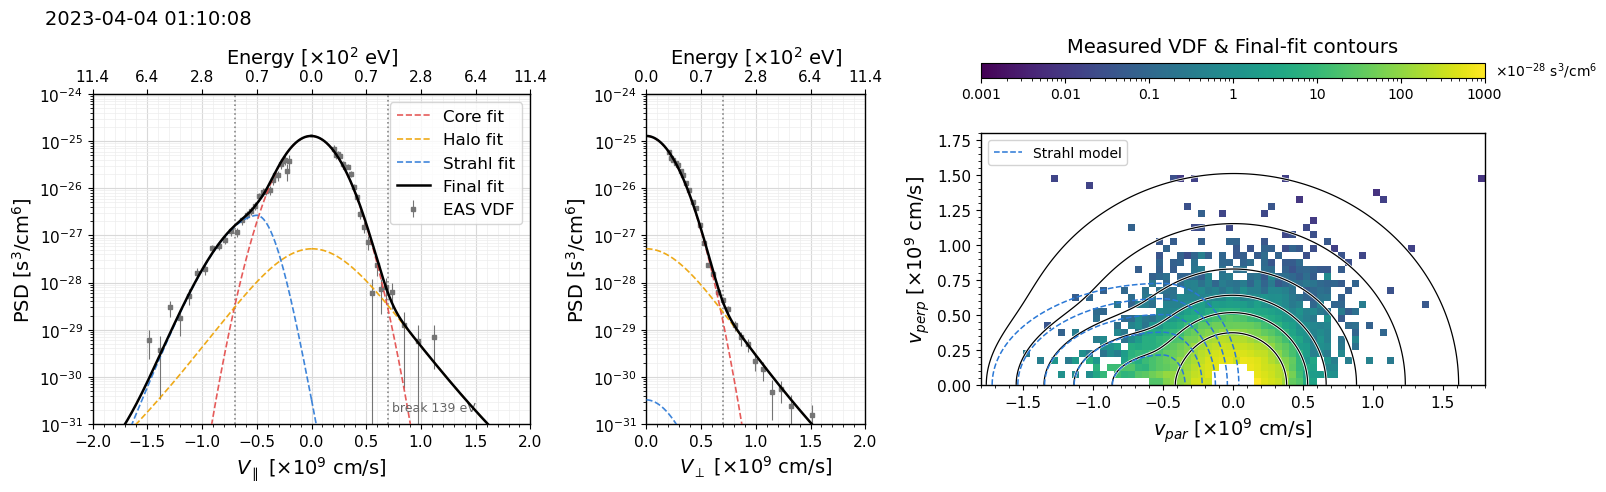

In [9]:
import json
from evdf_poisson import componentMomentsFromParams

referenceSummary = pd.read_csv(RESULTS_DIR / 'summary.csv').set_index('epoch_index')
fitParams = json.loads(referenceSummary.loc[EPOCH, 'fit_params_json'])
breakEnergyEv = float(referenceSummary.loc[EPOCH, 'break_energy_eV'])

fig = plotMeasuredVdf(grid, psd, counts, params=fitParams, breakEnergyEv=breakEnergyEv,
                      timeLabel=str(epochTime))
physical = componentMomentsFromParams(fitParams)
pd.Series(physical).round(3).to_frame('reference fit')

## 5. The pitch-angle distribution (PAD)

Averaging the PSD over pitch-angle bins at every energy gives the PAD. Normalised per
energy step, it shows where the electrons of that energy go:

- the core is nearly isotropic (flat in pitch angle);
- the strahl is a bright band near 0 or 180 deg at energies above the core. Here it
  sits near 180 deg: the field points sunward and the strahl streams anti-sunward.

The strahl side and width are measured from the PAD before the fit (notebook 03),
because the fit needs to know where to put the beam.

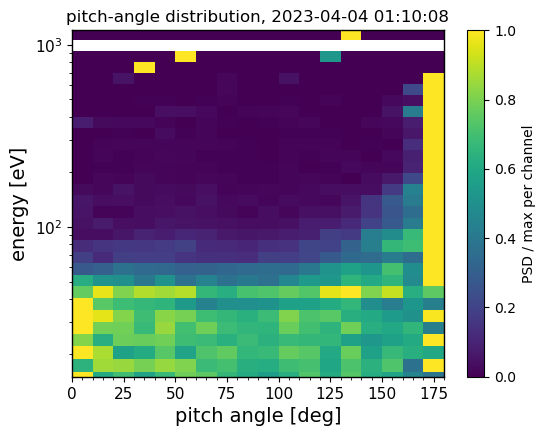

In [10]:
from evdf_poisson.plotting import plotPadSpectrogram

ax = plotPadSpectrogram(EXAMPLE_FILE, EPOCH)
ax.set_title(f'pitch-angle distribution, {epochTime}');

## 6. Spacecraft potential and the low-energy cut

- The spacecraft charges a few volts positive, so every electron arrives with that
  extra energy. RPW measures the potential $\phi_{sc}$; the preprocessing subtracts it
  from the energy of every measurement (`scpot_aligned` in the file).
- Below about 14 eV in the spacecraft frame the signal is dominated by **secondary and
  photo-electrons** from the spacecraft itself. The fit ignores energies below
  $14\,\text{eV} - \phi_{sc}$ (the `valid` mask of the grid).

spacecraft potential 2.78 V -> low-energy cut 11.2 eV


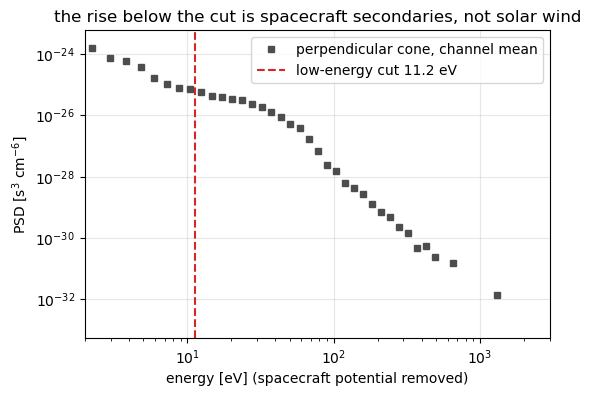

In [11]:
from evdf_poisson.epoch_io import SECONDARY_ELECTRON_CUT_EV, PSD_TO_CGS, KM_TO_CM
from evdf_poisson.models import ELECTRON_MASS_G, ERG_PER_EV

with h5py.File(EXAMPLE_FILE, 'r') as h5:
    spacecraftPotential = float(h5['scpot_aligned'][EPOCH])
    rawPixels = h5['pa_vec_in'][EPOCH]
lowEnergyCut = SECONDARY_ELECTRON_CUT_EV - spacecraftPotential
print(f'spacecraft potential {spacecraftPotential:.2f} V -> low-energy cut {lowEnergyCut:.1f} eV')

# perpendicular-cone channel means of the raw file, including energies below the cut
rawSpeed = np.sqrt((rawPixels[:, :, 2] * KM_TO_CM) ** 2 + (rawPixels[:, :, 3] * KM_TO_CM) ** 2)
rawEnergy = 0.5 * ELECTRON_MASS_G * rawSpeed ** 2 / ERG_PER_EV
perpCone = (rawPixels[:, :, 0] > 75) & (rawPixels[:, :, 0] < 105) & np.isfinite(rawEnergy)
channelEnergy = np.array([np.nanmedian(rawEnergy[row][perpCone[row]]) if perpCone[row].any() else np.nan for row in range(64)])
channelMean = np.array([np.nanmean(rawPixels[row, :, 1][perpCone[row]]) * PSD_TO_CGS if perpCone[row].any() else np.nan for row in range(64)])

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(channelEnergy, channelMean, 's', color='0.3', markersize=4, label='perpendicular cone, channel mean')
ax.axvline(lowEnergyCut, color='#d62728', linestyle='--', label=f'low-energy cut {lowEnergyCut:.1f} eV')
ax.set_xlabel('energy [eV] (spacecraft potential removed)'); ax.set_ylabel(r'PSD [s$^3$ cm$^{-6}$]')
ax.set_xlim(2, 3000); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('the rise below the cut is spacecraft secondaries, not solar wind');

## 7. The break energy

The **break energy** separates the core from the suprathermal electrons (halo and
strahl). It is found before the fit, from the perpendicular cone only (no strahl there):
a Maxwellian core and a power-law tail are fitted jointly to the cone spectrum, and the
break is where the two contribute equally (notebook 03).

The fit uses it to select the pixels of the core stage (below the break) and of the halo
stage (above), and to scale the strahl detection band. The dotted lines in the cuts
above mark it. For this epoch: about 139 eV, roughly 8 times the core temperature.

In [12]:
breakTable = pd.read_csv(EXAMPLE_DIR / (EXAMPLE_FILE.stem + '_two_population_crossing.csv'))
breakTable[['epoch_id', 'timestamp', 'scpot_V', 'break_E_eV', 'core_T_eV', 'tail_index', 'status']].round(2)

,epoch_id,timestamp,scpot_V,break_E_eV,core_T_eV,tail_index,status
0,0,2023-04-04 00:50:08,2.37,142.23,15.53,1.74,ok
1,1,2023-04-04 00:51:08,2.39,141.33,15.52,1.61,ok
2,2,2023-04-04 00:52:08,2.37,137.29,15.64,1.86,ok
3,3,2023-04-04 00:53:08,2.47,131.64,15.13,1.82,ok
4,4,2023-04-04 00:54:08,2.51,137.23,15.42,1.16,ok
5,5,2023-04-04 00:55:08,2.61,138.63,15.10,1.70,ok
6,6,2023-04-04 00:56:08,2.52,130.49,15.63,2.28,ok
7,7,2023-04-04 00:57:08,2.49,143.10,15.58,0.21,ok
8,8,2023-04-04 00:58:08,2.79,135.94,15.65,1.26,ok
9,9,2023-04-04 00:59:08,2.80,137.72,14.91,0.20,ok


## 8. Why zero-count pixels are data

Above 200 eV, 9 pixels in 10 registered nothing (table of section 1).

- A fit that keeps only pixels with counts > 0 sees only the upward fluctuations of a
  faint tail, and is pushed up.
- A Poisson likelihood gives a zero-count pixel with expected counts $\mu$ the
  probability $e^{-\mu}$, so empty pixels keep pulling the model down.

This is the central idea of the pipeline (notebook 07). Below: the fraction of
zero-count pixels per energy step in the parallel, anti-parallel and perpendicular
cones.

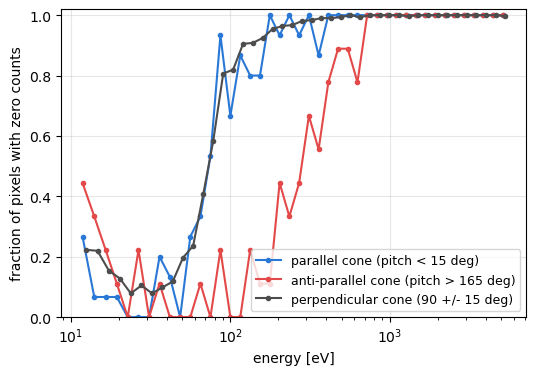

In [13]:
from evdf_poisson.plotting import wingMask

fig, ax = plt.subplots(figsize=(6, 4))
for wingName, label, color in (('par', 'parallel cone (pitch < 15 deg)', '#2a78d6'),
                               ('anti', 'anti-parallel cone (pitch > 165 deg)', '#e34948'),
                               ('perp', 'perpendicular cone (90 +/- 15 deg)', '0.3')):
    cone = wingMask(grid, wingName)
    energies = np.array([np.median(grid['energy_eV'][row][cone[row]]) if cone[row].any() else np.nan for row in range(64)])
    zeroFraction = np.array([np.mean(counts[row][cone[row]] == 0) if cone[row].any() else np.nan for row in range(64)])
    ax.semilogx(energies, zeroFraction, 'o-', markersize=3, color=color, label=label)
ax.set_xlabel('energy [eV]'); ax.set_ylabel('fraction of pixels with zero counts')
ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=9);

## Summary

- EAS delivers **counts** on a 64 x 1024 grid per minute. The one-count level $g$
  converts them to PSD and is known for every pixel.
- MAG gives the field direction; the fit works in the gyrotropic
  $(v_\parallel, v_\perp)$ plane.
- Three components: Maxwellian **core**, kappa **halo**, field-aligned **strahl**.
- Two inputs are measured before the fit: the strahl side and width (PAD) and the
  **break energy** (notebook 03).
- Above ~100 eV most pixels are zeros. That is data, and the Poisson objective uses
  it (notebooks 05 and 07).